# Naive Baseline 

In [3]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [5]:
# Load the raw appointment records CSV file into a pandas DataFrame
df= pd.read_csv(r'C:\Users\telvi\Downloads\AMDARI\nexora_care_flow\data\processed_data\AppointmentRecords_feature_eng.csv')

In [6]:
# Display the first five rows to inspect the dataset structure and values
df.head()

,AppointmentDateTime,appointment_volume,is_holiday,day_of_week
0,2024-01-01,31,1,0
1,2024-01-02,221,0,1
2,2024-01-03,167,0,2
3,2024-01-04,171,0,3
4,2024-01-05,103,0,4


In [7]:
# Generate summary statistics for all numerical and categorical columns
df.describe(include = 'all')

,AppointmentDateTime,appointment_volume,is_holiday,day_of_week
count,731,731.000000,731.000000,731.000000
unique,731,NaN,NaN,NaN
top,2024-01-01,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,176.953488,0.035568,2.991792
std,NaN,93.651119,0.185337,2.002037
min,NaN,7.000000,0.000000,0.000000
25%,NaN,108.500000,0.000000,1.000000
50%,NaN,197.000000,0.000000,3.000000
75%,NaN,249.500000,0.000000,5.000000


In [8]:
# Display information about the DataFrame, including columns, data types, and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   AppointmentDateTime  731 non-null    object
 1   appointment_volume   731 non-null    int64 
 2   is_holiday           731 non-null    int64 
 3   day_of_week          731 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 23.0+ KB


In [9]:
# AppointmentDateTime needs to be treated as a datetime variable
df['AppointmentDateTime'] = pd.to_datetime(df['AppointmentDateTime'])

In [10]:
# Check the data types to confirm the conversion
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   AppointmentDateTime  731 non-null    datetime64[ns]
 1   appointment_volume   731 non-null    int64         
 2   is_holiday           731 non-null    int64         
 3   day_of_week          731 non-null    int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 23.0 KB


In [11]:
#verify if data type of the AppointmentDateTime column has changed to datetype 
df['AppointmentDateTime'].dtype

dtype('<M8[ns]')

In [12]:
df.isnull().sum()

AppointmentDateTime    0
appointment_volume     0
is_holiday             0
day_of_week            0
dtype: int64

In [ ]:
# Count the number of appointments that occurred each day.
# .dt.date removes the time and keeps only the date.
daily_appointment = (
    df.groupby(df["AppointmentDateTime"].dt.date)
      .size()
      .reset_index(name="appointment_volume ")
)

# Set AppointmentDateTime as the index.
# asfreq("D") ensures that we have one row for every day.
# If a day has no appointments, AppointmentVolume becomes 0.

daily_appointment = ( daily_appointment .set_index("AppointmentDateTime") .asfreq("D", fill_value=0) )
# Create a daily holiday indicator.
# .first() means that if ANY appointment on that day
# is marked as a holiday, the whole day is treated as a holiday.

daily_features = ( df.groupby(df["AppointmentDateTime"].dt.date
                              )[ ["is_holiday", "day_of_week"] ] .first() )

# Convert the feature index to datetime format.
daily_features.index = pd.to_datetime(daily_features.index)
# Add the features to the daily appointment dataset. 
daily_appointment[["is_holiday", "day_of_week"]] = ( daily_features .reindex(daily_appointment.index) )


In [54]:
# Fill any missing feature values. 
daily_appointment["is_holiday"] = ( daily_appointment["is_holiday"] .fillna(0) .astype(int) )

In [55]:
# Calculate day_of_week directly from the date. 
# # Monday = 0 and Sunday = 6.
daily_appointment["day_of_week"] = ( daily_appointment.index.dayofweek )
# Display the first five rows. 
daily_appointment.head()

,appointment_volume,is_holiday,day_of_week
AppointmentDateTime,,,
2024-01-01,1,1,0
2024-01-02,1,0,1
2024-01-03,1,0,2
2024-01-04,1,0,3
2024-01-05,1,0,4


In [59]:
print(daily_appointment.columns)

Index(['appointment_volume ', 'is_holiday', 'day_of_week'], dtype='object')


In [60]:
# Remove any extra spaces from the column names

daily_appointment.columns = daily_appointment.columns.str.strip()

# Display the column names to confirm

print(daily_appointment.columns)

Index(['appointment_volume', 'is_holiday', 'day_of_week'], dtype='object')


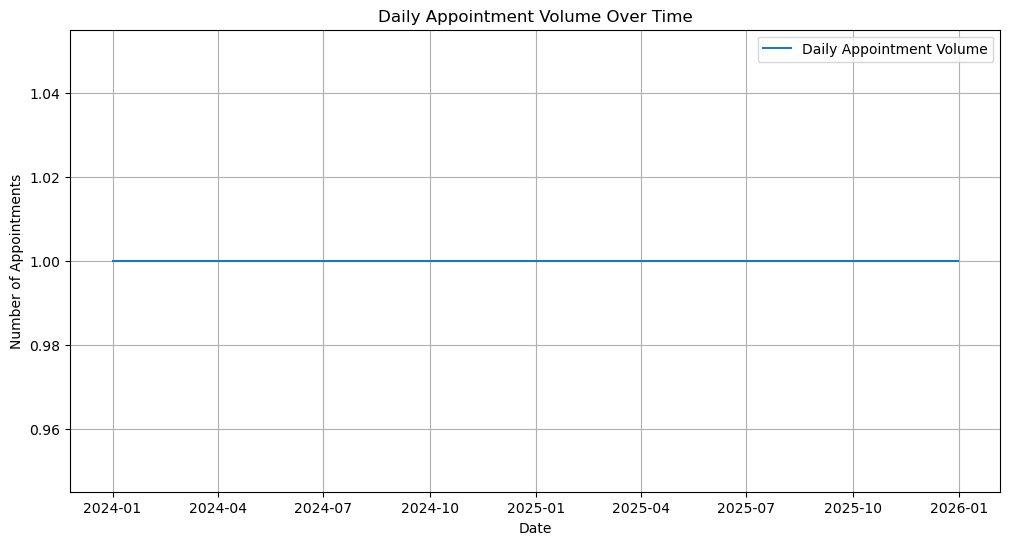

In [64]:
# Plot daily appointment volume over time

plt.figure(figsize=(12, 6))

plt.plot(
    daily_appointment.index,
    daily_appointment["appointment_volume"],
    label="Daily Appointment Volume"
)

plt.title("Daily Appointment Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Appointments")
plt.legend()
plt.grid(True)

plt.show()

Time Based Term / Train Split

In [65]:
# test_weeks = 8 → you want to test the model over 8 weeks
# 7 → there are 7 days in a week
# test_size = 56 → 8 × 7 = 56 days

# Number of weeks to use for testing
test_weeks = 8

# Convert the number of test weeks into number of days
test_size = test_weeks * 7

# Use all observations except the final 56 days for training
train = daily_appointment.iloc[:-test_size]

# Use the final 56 days for testing
test = daily_appointment.iloc[-test_size:]

# Check the size of each dataset
print("Training observations:", len(train))
print("Testing observations:", len(test))

# Check the date ranges
print("\nTraining period:")
print(train.index.min(),  train.index.max())

print("\nTesting period:")
print(test.index.min(), test.index.max())

Training observations: 675
Testing observations: 56

Training period:
2024-01-01 00:00:00 2025-11-05 00:00:00

Testing period:
2025-11-06 00:00:00 2025-12-31 00:00:00
